<a href="https://colab.research.google.com/github/VIKAS-PURBIA/CLV_Prediction_Model/blob/main/clv_prediction_notebook_md.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Elevate Labs Internship — Project 2: Customer Lifetime Value (CLV) Prediction Model

### Dataset Links
* **Direct Download Link (Used automatically in Cell 1 below):** [online_retail_II.xlsx (UCI Repository)](https://archive.ics.uci.edu/ml/machine-learning-databases/00502/online_retail_II.xlsx)
* **Official Dataset Info Page:** [UCI Online Retail II Dataset](https://archive.ics.uci.edu/dataset/502/online+retail+ii)
* **Alternative CSV Mirror (Kaggle):** [Online Retail II UCI on Kaggle](https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci)

> **How to run:** Simply click **Runtime -> Run all** (in Google Colab) or **Run -> Run All Cells** (in Jupyter). The notebook automatically downloads the dataset, cleans it, trains the models, creates charts, and saves your final output files.

In [1]:
# Step 0: Install required packages (if missing) and download the dataset automatically
!pip install -q xgboost openpyxl scikit-learn pandas numpy matplotlib seaborn joblib

import os
import urllib.request
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

DATA_URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00502/online_retail_II.xlsx'
DATA_FILE = 'online_retail_II.xlsx'

if not os.path.exists(DATA_FILE) and not os.path.exists('online_retail_II.csv'):
    print('Downloading dataset from UCI repository (43.5 MB)... Please wait ~20-30 seconds.')
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)
    print('Download complete!')
else:
    print('Dataset file already present locally. Ready to proceed!')

Download complete!


## Step 1: Load and Clean the Transactional Data
In this step, we:
1. Load both years of transaction records (`2009-2010` and `2010-2011`).
2. Remove rows that have no `Customer ID` (since we cannot track a customer without an ID).
3. Remove cancelled orders (invoices starting with `'C'`) and invalid negative quantities/prices.
4. Calculate `TotalSpend = Quantity * Price` for every item purchased.

In [2]:
print('Loading dataset into memory (takes ~30-45 seconds for Excel)...')
if os.path.exists('online_retail_II.csv'):
    df = pd.read_csv('online_retail_II.csv', encoding='ISO-8859-1')
else:
    sheets = pd.read_excel('online_retail_II.xlsx', sheet_name=None)
    df = pd.concat(sheets.values(), ignore_index=True)

# Standardize column names
df.columns = [c.strip().replace(' ', '') for c in df.columns]
df = df.rename(columns={'InvoiceNo': 'Invoice', 'UnitPrice': 'Price'})

# Clean missing Customer IDs, duplicates, and cancellations
df = df.dropna(subset=['CustomerID']).drop_duplicates()
df['CustomerID'] = df['CustomerID'].astype(int).astype(str)
df['Invoice'] = df['Invoice'].astype(str)
df = df[~df['Invoice'].str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]

# Parse dates and compute line-item revenue
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['TotalSpend'] = df['Quantity'] * df['Price']

print(f'Cleaned Transactions: {len(df):,} rows')
print(f'Total Unique Customers: {df["CustomerID"].nunique():,}')
df.head()

Loading dataset into memory (takes ~30-45 seconds for Excel)...
Cleaned Transactions: 779,425 rows
Total Unique Customers: 5,878


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,TotalSpend
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


## Step 2: Feature Engineering (RFM + Time Split)
To make sure our model predicts **future** spending honestly without cheating (data leakage), we split the timeline:
* **Past Window (Observation Period):** Used to calculate customer habits (**Recency**, **Frequency**, **Average Order Value (AOV)**, **Tenure**, and **Unique Products**).
* **Future Window (Last 90 Days):** Used as the target (`Actual_LTV`) that our model learns to predict.

In [3]:
max_date = df['InvoiceDate'].max()
cutoff_date = max_date - pd.Timedelta(days=90)

past_df = df[df['InvoiceDate'] <= cutoff_date].copy()
future_df = df[df['InvoiceDate'] > cutoff_date].copy()

# Build RFM & behavioral features from the past window
features = past_df.groupby('CustomerID').agg(
    LastPurchase=('InvoiceDate', 'max'),
    FirstPurchase=('InvoiceDate', 'min'),
    Frequency=('Invoice', 'nunique'),
    HistoricalSpend=('TotalSpend', 'sum'),
    TotalItems=('Quantity', 'sum'),
    UniqueProducts=('StockCode', 'nunique')
).reset_index()

features['Recency'] = (cutoff_date - features['LastPurchase']).dt.days
features['Tenure'] = (cutoff_date - features['FirstPurchase']).dt.days + 1
features['AOV'] = features['HistoricalSpend'] / features['Frequency']
features['PurchaseVelocity'] = features['Tenure'] / features['Frequency']

# Calculate actual spending in the 90-day future window
target = future_df.groupby('CustomerID')['TotalSpend'].sum().reset_index()
target = target.rename(columns={'TotalSpend': 'Actual_LTV'})

# Merge features and target (customers with no future orders get Actual_LTV = 0)
dataset = pd.merge(features, target, on='CustomerID', how='left')
dataset['Actual_LTV'] = dataset['Actual_LTV'].fillna(0.0)

# Cap extreme 99.5th percentile bulk-buyer outliers for stable training
cap_limit = dataset['Actual_LTV'].quantile(0.995)
dataset['Target_Capped'] = np.clip(dataset['Actual_LTV'], 0, cap_limit)

print(f'Prepared customer dataset with {len(dataset):,} customers.')
dataset[['CustomerID', 'Recency', 'Frequency', 'AOV', 'HistoricalSpend', 'Actual_LTV']].head()

Prepared customer dataset with 5,281 customers.


,CustomerID,Recency,Frequency,AOV,HistoricalSpend,Actual_LTV
0,12346,235,12,6463.038333,77556.46,0.00
1,12347,39,6,567.065000,3402.39,1519.14
2,12348,158,4,427.350000,1709.40,310.00
3,12349,317,3,890.380000,2671.14,1757.55
4,12350,219,1,334.400000,334.40,0.00


## Step 3: Train & Validate Regression Models (Random Forest vs. XGBoost)
We split the customers into **80% Training** and **20% Testing** sets, train both **Random Forest** and **XGBoost** regressors, and measure accuracy using **MAE** (Mean Absolute Error) and **RMSE** (Root Mean Squared Error).

In [4]:
feature_cols = [
    'Recency', 'Frequency', 'AOV', 'HistoricalSpend',
    'Tenure', 'UniqueProducts', 'PurchaseVelocity'
]

X = dataset[feature_cols]
y = dataset['Target_Capped']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Log-transform target to handle skewed spending values
y_train_log = np.log1p(y_train)

# 1. Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train_log)
rf_preds = np.maximum(0, np.expm1(rf_model.predict(X_test)))

# 2. XGBoost Regressor
xgb_model = XGBRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=5,
    subsample=0.8, colsample_bytree=0.8, random_state=42
)
xgb_model.fit(X_train, y_train_log)
xgb_preds = np.maximum(0, np.expm1(xgb_model.predict(X_test)))

def print_metrics(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    print(f'{name:15s} -> MAE: {mae:7.2f} | RMSE: {rmse:7.2f} | R2 Score: {r2:.4f}')

print('=== Model Validation Performance ===')
print_metrics('Random Forest', y_test, rf_preds)
print_metrics('XGBoost', y_test, xgb_preds)

# Save the trained XGBoost model
joblib.dump(xgb_model, 'xgb_clv_model.joblib')
print('\nSaved trained model to: xgb_clv_model.joblib')

=== Model Validation Performance ===
Random Forest   -> MAE:  354.16 | RMSE:  996.39 | R2 Score: 0.3738
XGBoost         -> MAE:  360.55 | RMSE: 1012.05 | R2 Score: 0.3540

Saved trained model to: xgb_clv_model.joblib


## Step 4: Customer Segmentation, Visualizations & Final CSV Export
Finally, we predict LTV for every customer, group them into 4 marketing tiers (**Bronze**, **Silver**, **Gold**, **Platinum**), save `final_ltv_predictions.csv`, and generate summary charts.

Saved final predictions to: final_ltv_predictions.csv


,Customer_Count,Avg_Recency_Days,Avg_Frequency,Avg_Predicted_LTV
Customer_Segment,,,,
Bronze (Low-Value),1585,372.66,2.01,0.910000
Silver (Growth),1584,212.35,3.06,6.260000
Gold (Loyal),1584,94.89,6.29,110.500000
Platinum (VIP),528,32.83,23.35,1627.410034


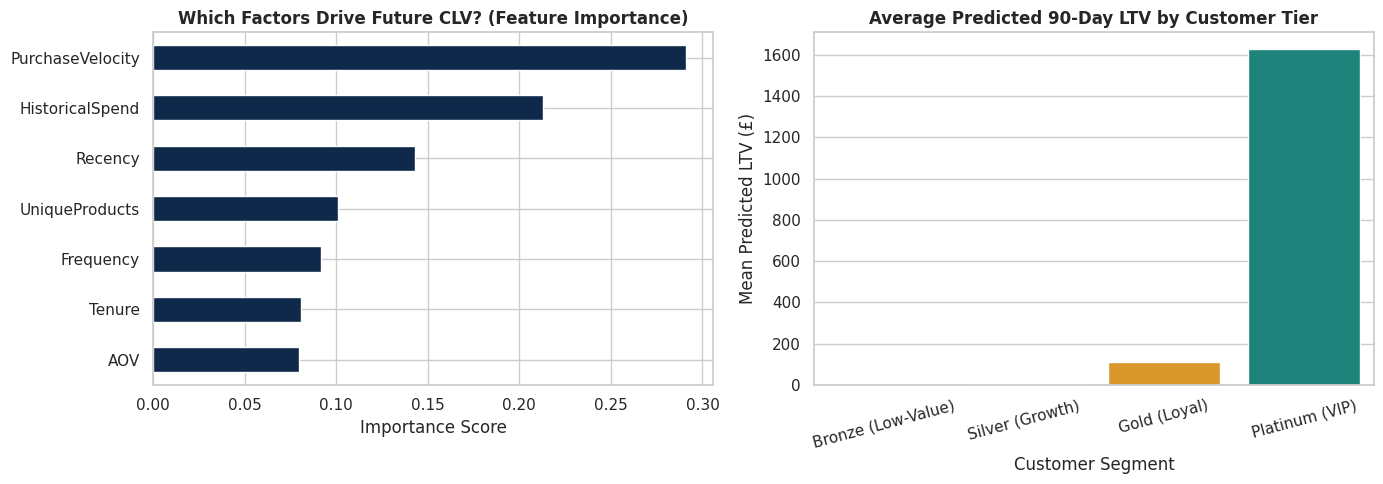

Saved charts to: clv_visualizations.png


In [5]:
# Predict LTV across all customers
dataset['Predicted_LTV'] = np.maximum(0, np.expm1(xgb_model.predict(X))).round(2)

# Assign 4 customer tiers based on predicted value
dataset['Customer_Segment'] = pd.qcut(
    dataset['Predicted_LTV'].rank(method='first'),
    q=[0, 0.30, 0.60, 0.90, 1.0],
    labels=['Bronze (Low-Value)', 'Silver (Growth)', 'Gold (Loyal)', 'Platinum (VIP)']
)

# Export final predictions CSV
output_cols = [
    'CustomerID', 'Recency', 'Frequency', 'AOV',
    'HistoricalSpend', 'Actual_LTV', 'Predicted_LTV', 'Customer_Segment'
]
final_csv = dataset[output_cols].sort_values(by='Predicted_LTV', ascending=False)
final_csv.to_csv('final_ltv_predictions.csv', index=False)
print('Saved final predictions to: final_ltv_predictions.csv')

# Display segment summary table
summary = final_csv.groupby('Customer_Segment', observed=False).agg(
    Customer_Count=('CustomerID', 'count'),
    Avg_Recency_Days=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Predicted_LTV=('Predicted_LTV', 'mean')
).round(2)
display(summary)

# Generate and save visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

importances = pd.Series(xgb_model.feature_importances_, index=feature_cols).sort_values()
importances.plot(kind='barh', ax=axes[0], color='#0f294a')
axes[0].set_title('Which Factors Drive Future CLV? (Feature Importance)', fontweight='bold')
axes[0].set_xlabel('Importance Score')

sns.barplot(
    data=summary.reset_index(), x='Customer_Segment', y='Avg_Predicted_LTV',
    ax=axes[1], palette=['#94a3b8', '#38bdf8', '#f59e0b', '#0d9488']
)
axes[1].set_title('Average Predicted 90-Day LTV by Customer Tier', fontweight='bold')
axes[1].set_xlabel('Customer Segment')
axes[1].set_ylabel('Mean Predicted LTV (£)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('clv_visualizations.png', dpi=300)
plt.show()
print('Saved charts to: clv_visualizations.png')